In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures

house_df = pd.read_csv('kc_house_data.csv')

## Exercise 1
a) Create and train simple regression model of sqft_living to price.  
b) Evaluate and visualise created model.  
c) Create and plot higher order polynomial regression models.

In [6]:
#a)

X = house_df.sqft_living.values.reshape(-1,1)[:1000]
y = house_df.price.values.reshape(-1)[:1000]

model = LinearRegression() 

#Your code:
model.fit(X, y)

#Hint: .fit()

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[269.46]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3.23e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[28064.74]


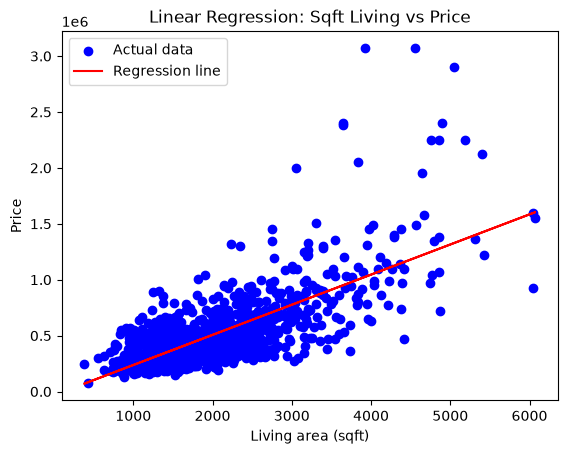

In [ ]:
#b)

y_pred = model.predict(X)
 
plt.scatter(X, y, color='blue', label='Data')
plt.plot(X, y_pred, color='red', label='Regression line')

plt.xlabel('Living area (sqft)')
plt.ylabel('Price')
plt.title('Sqft Living vs Price')
plt.legend()
plt.show()

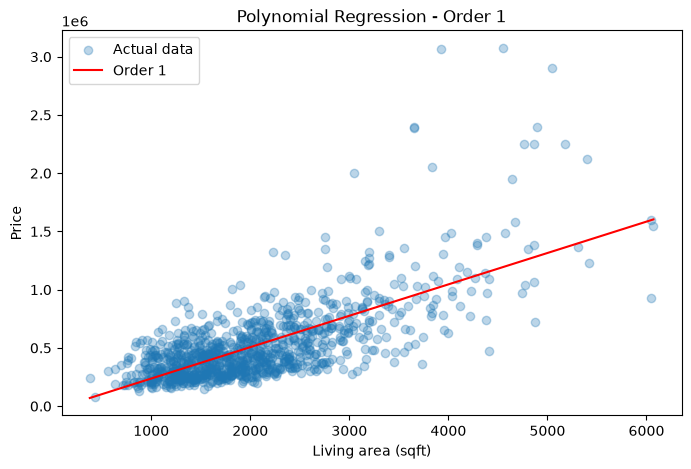

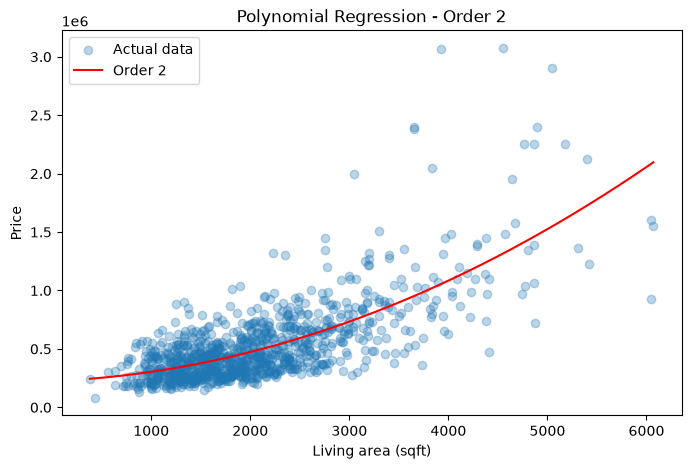

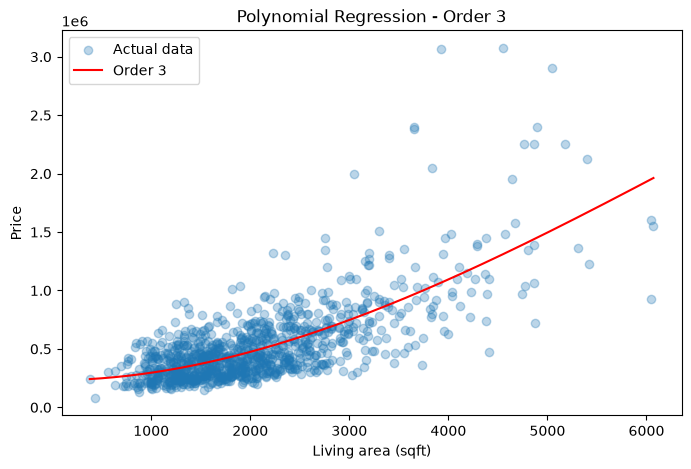

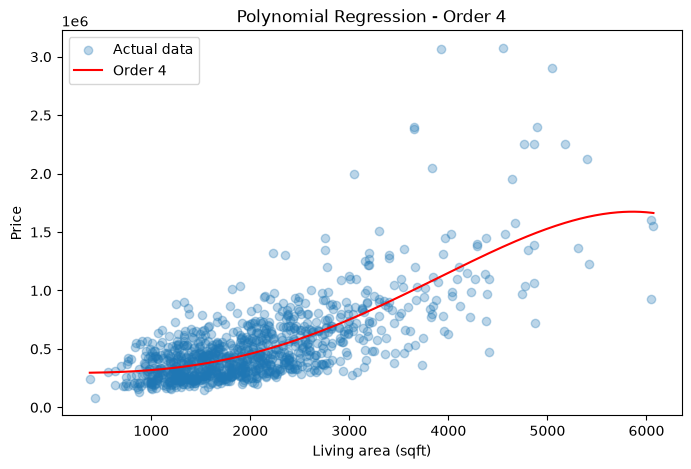

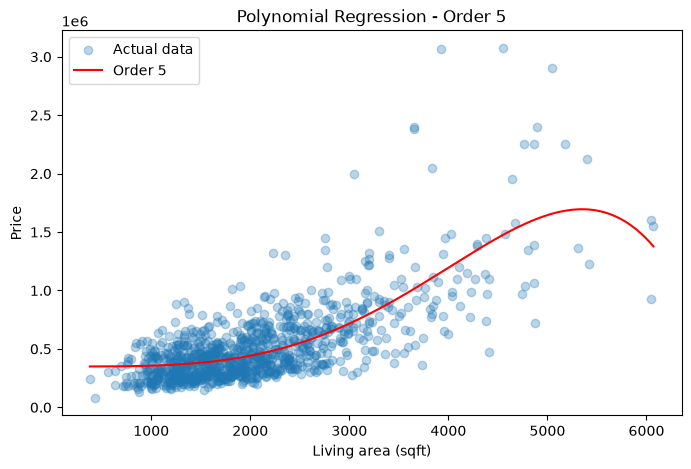

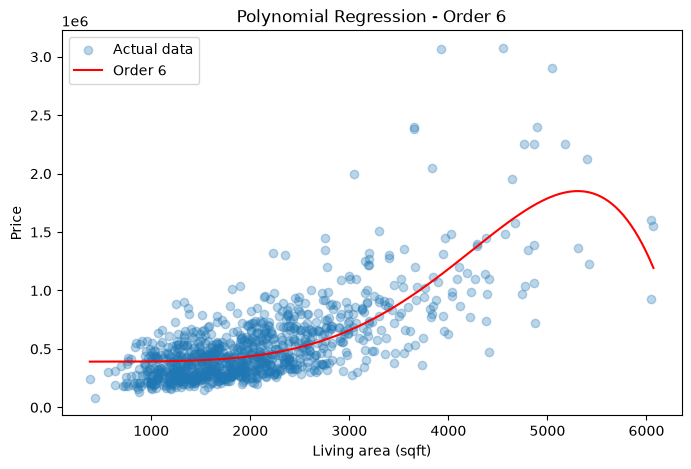

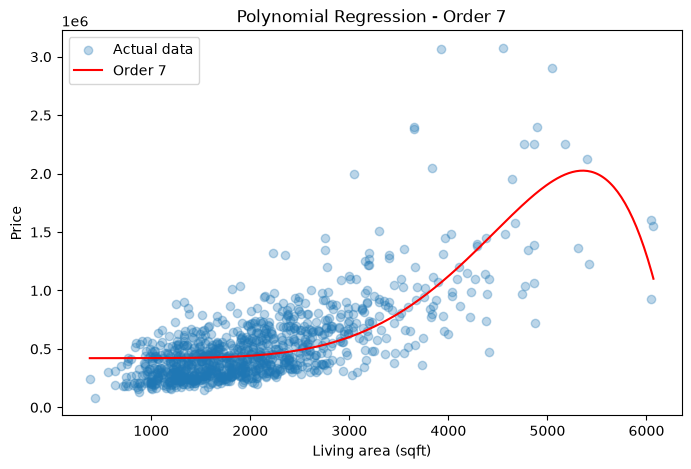

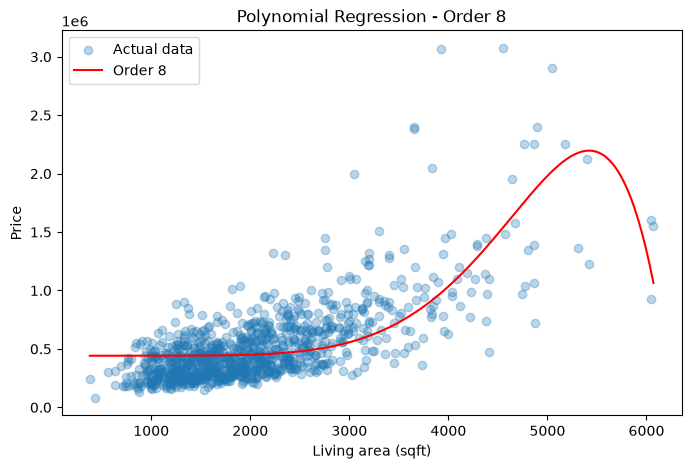

In [ ]:
#c)

for order in range(1, 9):

    poly = PolynomialFeatures(order, include_bias=False)
    X_order = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_order, y)

    X_plot = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)

    X_plot_order = poly.transform(X_plot)

    y_pred = model.predict(X_plot_order)

    plt.figure(figsize=(8, 5))
    plt.scatter(X, y, label='Data')
    plt.plot(X_plot, y_pred, color='red', label=f'Order {order}')

    plt.xlabel('Living area (sqft)')
    plt.ylabel('Price')
    plt.title(f'Polynomial Regression - Order {order}')
    plt.legend()
    plt.show()


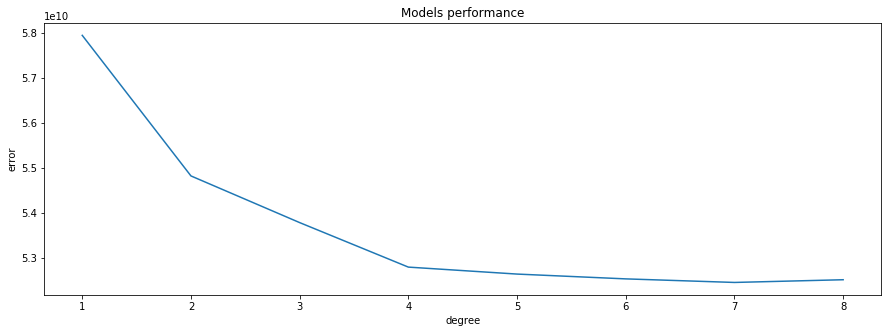

In [5]:
#Your code:


The commentary on excercise 1:
We see an obvious correlation between price and areo of space and the best model in my opinion is the model with 6th order since additional corrections dont seem to be neccessery. We see the prices for sqrfeet rise but then they drop with the highest areas. The predition line looks correct

## Exercise 2
In reality, we are not given the full dataset, so we need to create models which are able to handle unknown data.  
a) Split your data into training sample and test sample and repeat exercise 1 c). Plot training and test errors for all models. 

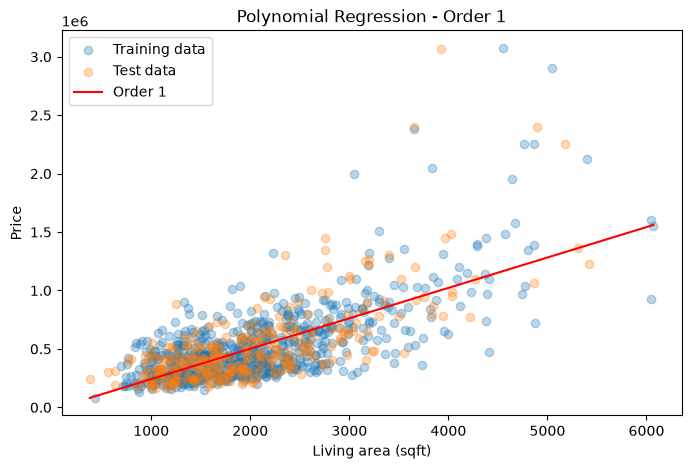

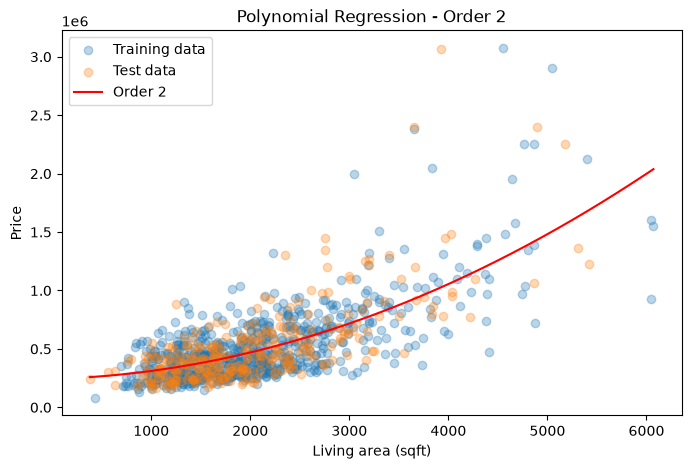

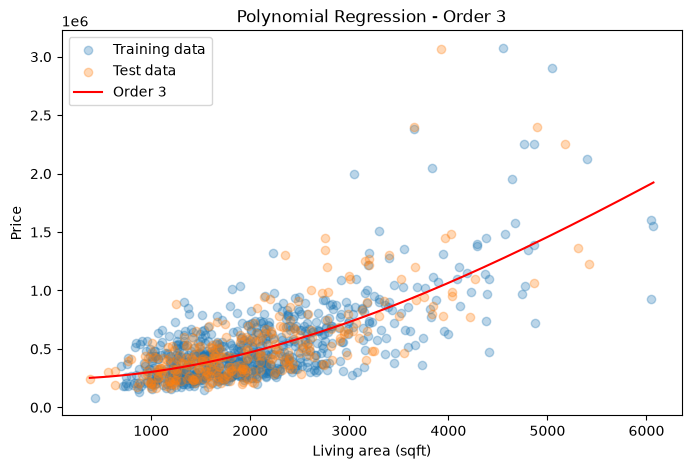

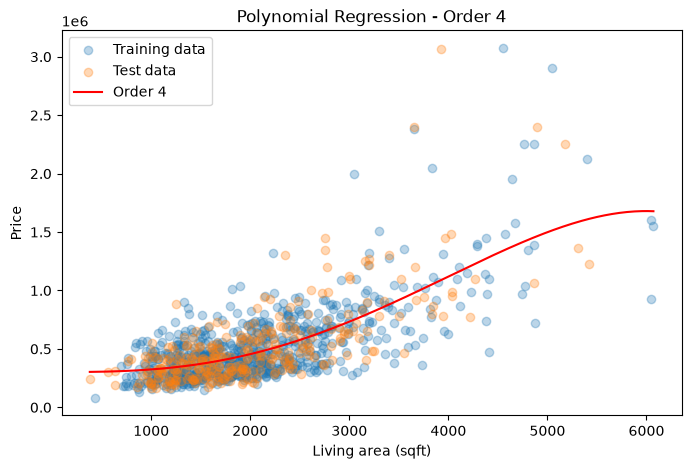

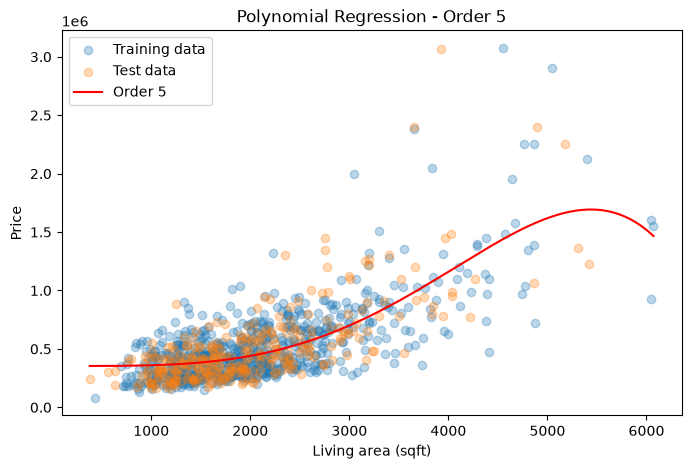

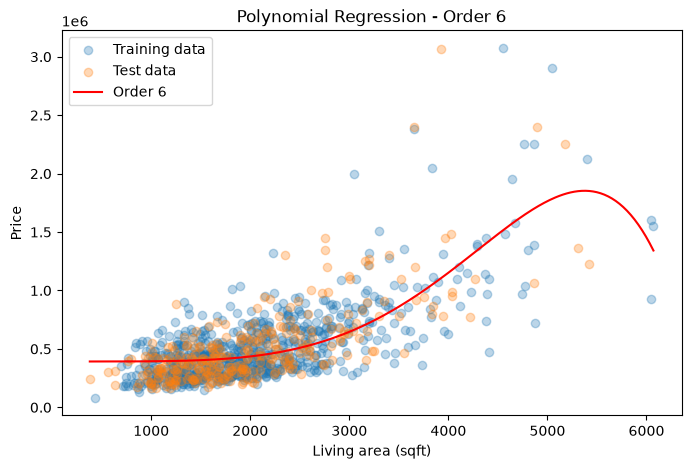

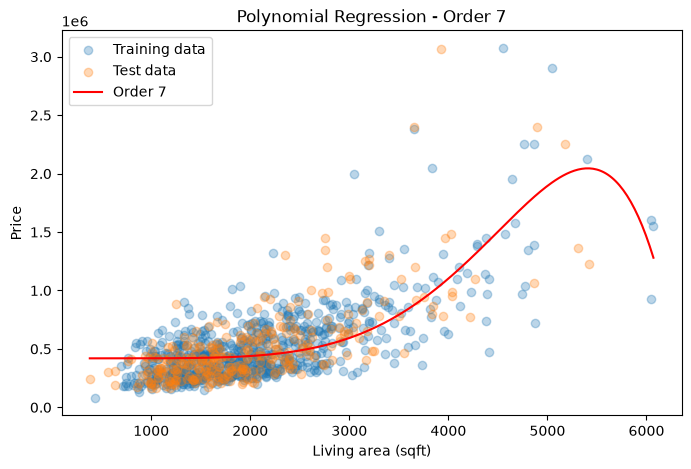

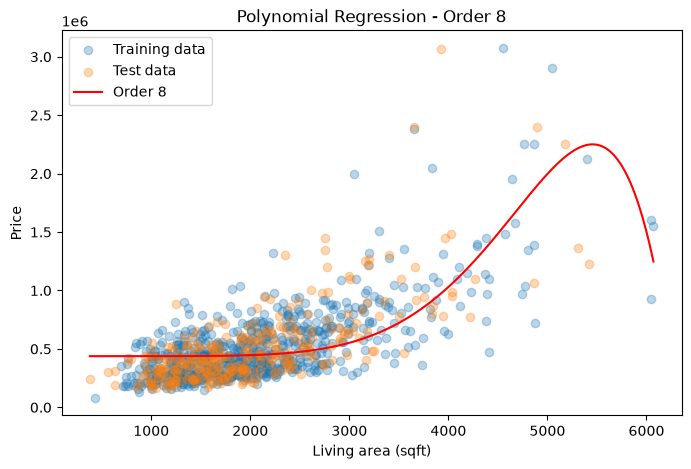

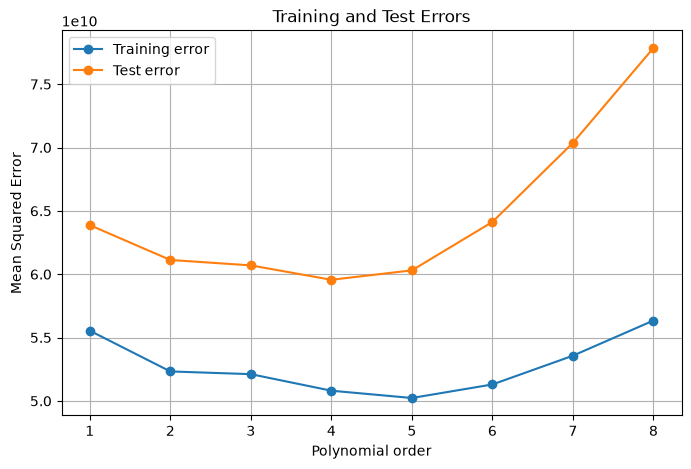

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=44
)

train_errors = []
test_errors = []

for order in range(1, 9):

    poly = PolynomialFeatures(order, include_bias=False)

    X_train_order = poly.fit_transform(X_train)
    X_test_order = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_order, y_train)

    y_train_pred = model.predict(X_train_order)
    y_test_pred = model.predict(X_test_order)

    train_error = mean_squared_error(y_train, y_train_pred)
    test_error = mean_squared_error(y_test, y_test_pred)

    train_errors.append(train_error)
    test_errors.append(test_error)

    X_plot = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
    X_plot_order = poly.transform(X_plot)
    y_plot = model.predict(X_plot_order)

    plt.figure(figsize=(8, 5))
    plt.scatter(X_train, y_train, label='Training data')
    plt.scatter(X_test, y_test, label='Test data')
    plt.plot(X_plot, y_plot, color='red', label=f'Order {order}')

    plt.xlabel('Living area (sqft)')
    plt.ylabel('Price')
    plt.title(f'Polynomial Regression - Order {order}')
    plt.legend()
    plt.show()


plt.figure(figsize=(8, 5))

plt.plot(range(1, 9), train_errors, marker='o', label='Training error')
plt.plot(range(1, 9), test_errors, marker='o', label='Test error')

plt.xlabel('Polynomial order')
plt.ylabel('Mean Squared Error')
plt.title('Training and Test Errors')
plt.xticks(range(1, 9))
plt.legend()
plt.grid()
plt.show()

The commentary on excercise 2
Splitting the dataset into training and test samples allows us to evaluate how well the regression models predict unknown data. As the polynomial order increases, the training error generally decreases because the model becomes more complex and can fit the training data more accurately. However, a higher polynomial order does not necessarily mean better predictions on new data.

## Exercise 3
a) Train model to predict sqft_living for a given house price. Plot predictions.  
b) Apply more features and propose better model for predicting house prices. Try to beat proposed one.

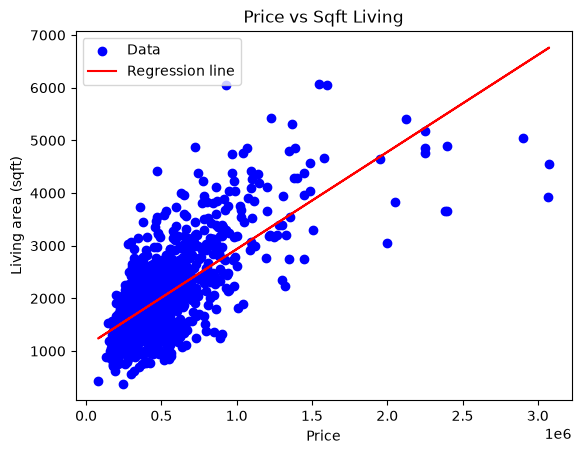

In [8]:
#a)

X = house_df.price.values.reshape(-1,1)[:1000]
y = house_df.sqft_living.values.reshape(-1)[:1000]

#Your code:
model.fit(X, y)
y_pred = model.predict(X)
 
plt.scatter(X, y, color='blue', label='Data')
plt.plot(X, y_pred, color='red', label='Regression line')

plt.xlabel('Price')
plt.ylabel('Living area (sqft)')
plt.title('Price vs Sqft Living')
plt.legend()
plt.show()

In [9]:
#b) Let's propose model, which uses living sqft, lot sqft, grade, view and all of their interactions up to third degree

X = house_df[['sqft_living', 'sqft_lot', 'grade', 'view']].values.reshape(-1,4)
y = house_df.price.values.reshape(-1)

poly = PolynomialFeatures(3, include_bias = False)
X = poly.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=43)
    
model = LinearRegression() 
_= model.fit(X_train, y_train) 

y_pred = model.predict(X_test)
print("Mean squared error equals: {0}".format(mean_squared_error(y_pred, y_test)))


#Your model:


Mean squared error equals: 127948491878.08809


We can see correlation between price and space it provides however the model I created seems to predict it not well because its of low order. I didnt come up with a better model for excercise b  

W